In [1]:
import pandas as pd
import numpy as np
import os

In [2]:
cd ../../

/home/mvillota/Documentos/Tesis/EmbryoDev_Assess


In [3]:
PATH_DATA = '../Datasets/Processed/hvwc23/'

In [4]:
train_folder = PATH_DATA + "train"
test_folder = PATH_DATA + "test"
train_csv_path = PATH_DATA + "train.csv"
test_csv_path = PATH_DATA + "test.csv"


train_df = pd.read_csv(train_csv_path)
train_df['image_path'] = train_df['Image'].apply(lambda x: os.path.join(train_folder, x))
train_df = train_df[['image_path', 'Class']].rename(columns={'Class': 'label'})


test_df = pd.read_csv(test_csv_path)
test_df['image_path'] = test_df['Image'].apply(lambda x: os.path.join(test_folder, x))
test_df['label'] = None  # Placeholder for test labels
test_df = test_df[['image_path', 'label']]


combined_df = pd.concat([train_df, test_df], ignore_index=True)

print(combined_df.head())
print(f"Total images: {len(combined_df)}")

missing_files = combined_df[~combined_df['image_path'].apply(os.path.exists)]
if not missing_files.empty:
    print(f"Warning: {len(missing_files)} images not found, e.g., {missing_files['image_path'].iloc[0]}")

                                      image_path label
0  ../Datasets/Processed/hvwc23/train/D3_405.jpg     0
1  ../Datasets/Processed/hvwc23/train/D3_523.jpg     0
2  ../Datasets/Processed/hvwc23/train/D3_750.jpg     0
3  ../Datasets/Processed/hvwc23/train/D3_427.jpg     0
4  ../Datasets/Processed/hvwc23/train/D3_042.jpg     0
Total images: 1020


In [5]:
df = combined_df

In [6]:
df.shape

(1020, 2)

In [7]:
df.columns

Index(['image_path', 'label'], dtype='object')

In [8]:
df.duplicated().sum()

0

In [9]:
df.isnull().sum()

image_path      0
label         180
dtype: int64

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1020 entries, 0 to 1019
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   image_path  1020 non-null   object
 1   label       840 non-null    object
dtypes: object(2)
memory usage: 16.1+ KB


In [11]:
df['label'].unique()

array([0, 1, None], dtype=object)

In [12]:
df['label'].value_counts()

0    716
1    124
Name: label, dtype: int64

TypeError: '<' not supported between instances of 'NoneType' and 'int'

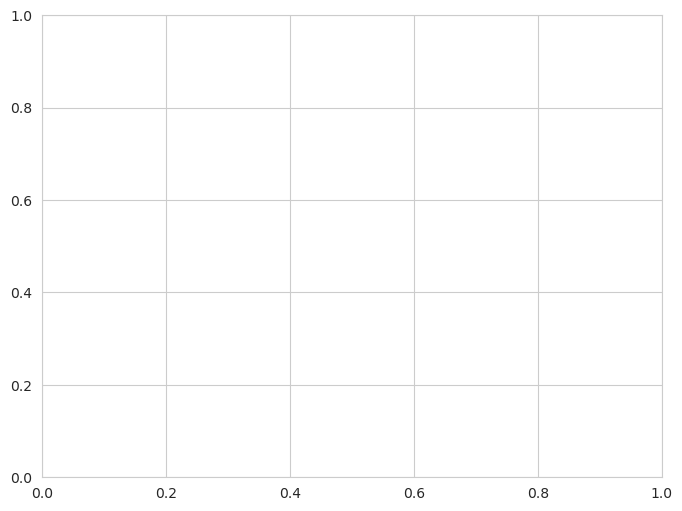

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_style("whitegrid")

fig, ax = plt.subplots(figsize=(8, 6))
sns.countplot(data=df, x="label", palette="viridis", ax=ax)

ax.set_title("Distribution Types", fontsize=14, fontweight='bold')
ax.set_xlabel("Embryo Type", fontsize=12)
ax.set_ylabel("Count", fontsize=12)

for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='bottom', fontsize=11, color='black', 
                xytext=(0, 5), textcoords='offset points')

plt.show()

label_counts = df["label"].value_counts()

fig, ax = plt.subplots(figsize=(8, 6))
colors = sns.color_palette("viridis", len(label_counts))

ax.pie(label_counts, labels=label_counts.index, autopct='%1.1f%%', 
       startangle=140, colors=colors, textprops={'fontsize': 12, 'weight': 'bold'},
       wedgeprops={'edgecolor': 'black', 'linewidth': 1})

ax.set_title("Distribution Types - Pie Chart", fontsize=14, fontweight='bold')

plt.show()

In [14]:
train_images = df[df['label'].notnull()]

In [15]:
good_images = train_images[train_images['label'] == 1]['image_path'].head(5).tolist()
not_good_images = train_images[train_images['label'] == 0]['image_path'].head(5).tolist()

def display_images(image_paths, title):
    plt.figure(figsize=(15, 5))
    for i, img_path in enumerate(image_paths):
        if os.path.exists(img_path):
            img = cv2.imread(img_path)
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)  # Convert BGR to RGB
            plt.subplot(1, 5, i + 1)
            plt.imshow(img)
            plt.title(f"{title} {i+1}")
            plt.axis('off')
        else:
            print(f"Image not found: {img_path}")
    plt.show()

In [16]:
import cv2

Good Embryos (Class 1):


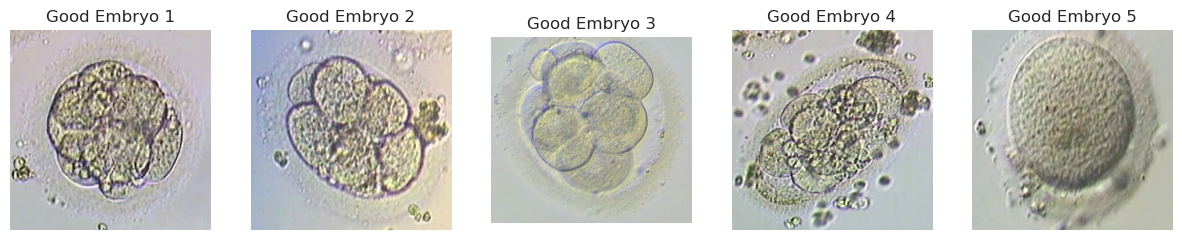

Not Good Embryos (Class 0):


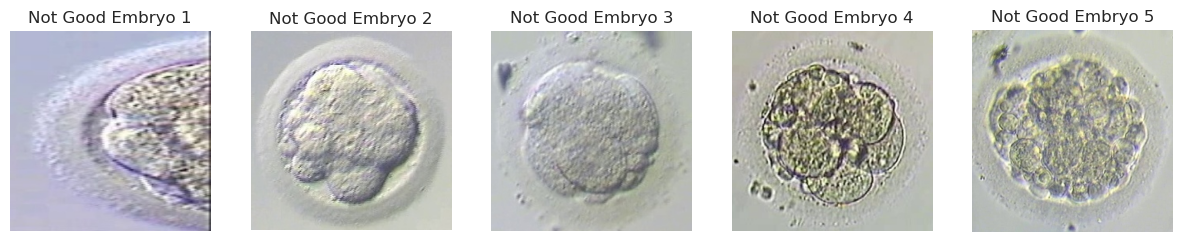

In [17]:
print("Good Embryos (Class 1):")
display_images(good_images, "Good Embryo")
print("Not Good Embryos (Class 0):")
display_images(not_good_images, "Not Good Embryo")

In [18]:
from sklearn.utils import resample

max_count = df['label'].value_counts().max()

dfs = []
for category in df['label'].unique():
    class_subset = df[df['label'] == category]
    if len(class_subset) == 0:
        continue  # skip empty classes
    class_upsampled = resample(class_subset,
                               replace=True,
                               n_samples=max_count,
                               random_state=42)
    dfs.append(class_upsampled)

df_balanced = pd.concat(dfs).sample(frac=1, random_state=42).reset_index(drop=True)

In [19]:
df = df_balanced

In [20]:
df

,image_path,label
0,../Datasets/Processed/hvwc23/train/D5_238.jpg,0
1,../Datasets/Processed/hvwc23/train/D5_003.jpg,1
2,../Datasets/Processed/hvwc23/train/D3_431.jpg,0
3,../Datasets/Processed/hvwc23/train/D3_173.jpg,0
4,../Datasets/Processed/hvwc23/train/D5_090.jpg,1
...,...,...
1427,../Datasets/Processed/hvwc23/train/D3_767.jpg,1
1428,../Datasets/Processed/hvwc23/train/D3_462.jpg,1
1429,../Datasets/Processed/hvwc23/train/D5_202.jpg,1
1430,../Datasets/Processed/hvwc23/train/D3_372.jpg,1


In [21]:
import pandas as pd
import numpy as np
import cv2
import os
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Conv2D, MaxPooling2D, BatchNormalization, ReLU, Flatten, Dense, Dropout, Input, GlobalAveragePooling2D, Layer
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import matplotlib.pyplot as plt
import seaborn as sns


def load_images(df, img_size=(224, 224)):
    images = []
    labels = []
    for idx, row in df.iterrows():
        if os.path.exists(row['image_path']):
            img = cv2.imread(row['image_path'])
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            img = cv2.resize(img, img_size)
            images.append(img)
            labels.append(row['label'])
    return np.array(images), np.array(labels)

X, y = load_images(df)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

datagen = ImageDataGenerator(
    rotation_range=10,
    horizontal_flip=True,
    fill_mode='nearest'
)
datagen.fit(X_train)

kg_triples = [
    "embryo, has_quality, blastocyst_expansion",
    "embryo, has_quality, cell_symmetry",
    "embryo, has_quality, inner_cell_mass",
    "embryo, has_quality, trophectoderm_quality"
]

def embed_triples(triples, embed_dim=64):
    tokenizer = tf.keras.preprocessing.text.Tokenizer()
    tokenizer.fit_on_texts(triples)
    sequences = tokenizer.texts_to_sequences(triples)
    padded = tf.keras.preprocessing.sequence.pad_sequences(sequences, maxlen=10, padding='post')
    embedding_layer = tf.keras.layers.Embedding(len(tokenizer.word_index) + 1, embed_dim)(padded)
    return embedding_layer

triple_embeddings = embed_triples(kg_triples)

class KGAttentionLayer(Layer):
    def __init__(self, embed_dim=64, **kwargs):
        super(KGAttentionLayer, self).__init__(**kwargs)
        self.embed_dim = embed_dim
        self.triple_queries = None
        self.cnn_keys = None
        self.cnn_values = None
        self.triple_keys = None
        self.triple_values = None
        self.input_queries = None

    def build(self, input_shape):
        self.triple_queries = Dense(self.embed_dim, activation=None)
        self.cnn_keys = Dense(self.embed_dim, activation=None)
        self.cnn_values = Dense(self.embed_dim, activation=None)
        self.triple_keys = Dense(self.embed_dim, activation=None)
        self.triple_values = Dense(self.embed_dim, activation=None)
        self.input_queries = Dense(self.embed_dim, activation=None)
        super(KGAttentionLayer, self).build(input_shape)

    def call(self, inputs):
        cnn_features, triple_embeds = inputs
        batch_size = tf.shape(cnn_features)[0]
        cnn_features_flat = GlobalAveragePooling2D()(cnn_features)
        triple_embeds = tf.repeat(triple_embeds, batch_size, axis=0)
        triple_embeds = tf.reshape(triple_embeds, (batch_size, -1, tf.shape(triple_embeds)[-2], self.embed_dim))
        triple_embeds_flat = tf.reduce_mean(triple_embeds, axis=2)
        triple_queries = self.triple_queries(triple_embeds_flat)
        cnn_keys = self.cnn_keys(cnn_features_flat)
        cnn_values = self.cnn_values(cnn_features_flat)
        attention_scores = tf.matmul(triple_queries, cnn_keys, transpose_b=True) / tf.math.sqrt(tf.cast(self.embed_dim, tf.float32))
        attention_weights = tf.nn.softmax(attention_scores, axis=-1)
        outward_agg = tf.matmul(attention_weights, cnn_values)
        triple_keys = self.triple_keys(triple_embeds_flat)
        triple_values = self.triple_values(triple_embeds_flat)
        input_queries = self.input_queries(cnn_features_flat)
        inward_scores = tf.matmul(input_queries, triple_keys, transpose_b=True) / tf.math.sqrt(tf.cast(self.embed_dim, tf.float32))
        inward_weights = tf.nn.softmax(inward_scores, axis=-1)
        inward_agg = tf.matmul(inward_weights, triple_values)
        outward_agg_flat = tf.reduce_mean(outward_agg, axis=1)
        inward_agg_flat = tf.reduce_mean(inward_agg, axis=1)
        combined_agg = tf.keras.layers.Concatenate()([outward_agg_flat, inward_agg_flat])
        return combined_agg

input_img = Input(shape=(224, 224, 3))
x = Conv2D(32, (3, 3), strides=(1, 1), padding='same')(input_img)
x = BatchNormalization()(x)
x = ReLU()(x)
x = Conv2D(64, (3, 3), strides=(1, 1), padding='same')(x)
x = BatchNormalization()(x)
x = ReLU()(x)
x = MaxPooling2D((3, 3), strides=(2, 2))(x)
x = Conv2D(32, (3, 3), strides=(1, 1), padding='same')(x)
x = BatchNormalization()(x)
x = ReLU()(x)
x = Conv2D(32, (3, 3), strides=(1, 1), padding='same')(x)
x = BatchNormalization()(x)
x = ReLU()(x)
x = MaxPooling2D((3, 3), strides=(2, 2))(x)
x = Conv2D(64, (3, 3), strides=(1, 1), padding='same')(x)
cnn_features = BatchNormalization()(x)
x = ReLU(name='re_lu_5')(cnn_features)
x = MaxPooling2D((5, 5), strides=(2, 2))(x)
x = Flatten()(x)
x = Dropout(0.4)(x)
kga_output = KGAttentionLayer(embed_dim=64)([cnn_features, triple_embeddings])
x = tf.keras.layers.Concatenate()([x, kga_output])
x = Dense(128, activation='relu')(x)
x = Dropout(0.4)(x)
output = Dense(2, activation='softmax')(x)
model = Model(inputs=input_img, outputs=output)
model.compile(optimizer=Adam(learning_rate=0.001), loss='sparse_categorical_crossentropy', metrics=['accuracy'])

history = model.fit(datagen.flow(X_train, y_train, batch_size=32),
                    epochs=25, validation_data=(X_test, y_test))

test_loss, test_accuracy = model.evaluate(X_test, y_test)
print(f"Test Accuracy: {test_accuracy*100:.2f}%")

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

y_pred = model.predict(X_test)
y_pred_classes = np.argmax(y_pred, axis=1)
cm = confusion_matrix(y_test, y_pred_classes)
plt.figure(figsize=(6, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Poor', 'Good'], yticklabels=['Poor', 'Good'])
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()
print("Classification Report:")
print(classification_report(y_test, y_pred_classes, target_names=['Poor', 'Good']))

def get_gradcam(model, img, layer_name='re_lu_5'):
    grad_model = Model([model.inputs], [model.get_layer(layer_name).output, model.output])
    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img)
        class_idx = tf.argmax(predictions[0])
        loss = predictions[:, class_idx]
    grads = tape.gradient(loss, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / tf.math.reduce_max(heatmap)
    return heatmap.numpy()

test_images = X_test[:5]
test_labels = y_test[:5]
test_paths = df.iloc[train_test_split(df.index, test_size=0.2, random_state=42, stratify=df['label'])[1]]['image_path'].values[:5]
predictions = model.predict(test_images)
plt.figure(figsize=(15, 10))
for i in range(5):
    img = test_images[i]
    heatmap = get_gradcam(model, img[np.newaxis, ...])
    heatmap = cv2.resize(heatmap, (224, 224))
    heatmap = np.uint8(255 * heatmap)
    heatmap = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)
    superimposed_img = heatmap * 0.4 + img
    superimposed_img = np.clip(superimposed_img, 0, 255).astype(np.uint8)
    pred_label = np.argmax(predictions[i])
    plt.subplot(3, 5, i+1)
    plt.imshow(img.astype(np.uint8))
    plt.title(f"Original\nTrue: {['Poor', 'Good'][test_labels[i]]}")
    plt.axis('off')
    plt.subplot(3, 5, i+6)
    plt.imshow(superimposed_img)
    plt.title(f"Grad-CAM\nPred: {['Poor', 'Good'][pred_label]}")
    plt.axis('off')
    plt.subplot(3, 5, i+11)
    plt.imshow(heatmap)
    plt.title("Heatmap")
    plt.axis('off')
plt.tight_layout()
plt.show()

ModuleNotFoundError: No module named 'tensorflow'